
# MACHINE LEARNING ASSIGNMENT 2

**BITS ID:** 2026CT05193

**Name:** Nagamuthulakshmi M

**Programme:** M.Tech AIML

**Subject:** Machine Learning

**Assignment:** Implementation and Comparative Analysis of Multiple Classification Models

## Project Objective

The objective of this project is to implement five machine learning classification algorithms using the UCI Adult Census Income dataset.

The models used are:
1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors
4. Gaussian Naive Bayes
5. Random Forest Classifier

The models will be evaluated using Accuracy, AUC, Precision, Recall, F1 Score and Matthews Correlation Coefficient (MCC).

The project also covers data cleaning, missing-value handling, duplicate removal, categorical encoding, feature scaling, class imbalance analysis and graphical comparison of model performance.


## 1. Problem Statement

The aim of this project is to develop machine learning classification models to predict whether an individual's annual income exceeds $50,000 based on census-related information.

The dataset contains demographic, educational and employment-related attributes.

Five classification algorithms are implemented on the same dataset using an 80:20 stratified train-test split.

The performance of each algorithm is compared using six evaluation metrics to identify the most suitable classification model for the selected dataset.


**Install the required libraries**

In [252]:

!pip install -q ucimlrepo joblib


**Import libraries**

In [253]:

import os
import sys
import time
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 5193

os.makedirs("model", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")
print("Python version:", sys.version)
print("Random seed:", RANDOM_STATE)


Libraries imported successfully!
Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Random seed: 5193


**Download the dataset**

In [254]:

# Download the Adult dataset from UCI

adult = fetch_ucirepo(id=2)

# Extract input features
X_raw = adult.data.features.copy()

# Extract target variable
y_raw = adult.data.targets.iloc[:, 0].copy()

# Combine features and target
df_raw = X_raw.copy()
df_raw["income"] = y_raw.values

print("Dataset downloaded successfully!")
print("Dataset shape:", df_raw.shape)

display(df_raw.head())


Dataset downloaded successfully!
Dataset shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


**Dataset description**

## 2. Dataset Description

The Adult Census Income dataset is obtained from the UCI Machine Learning Repository.

It contains 48,842 records and 14 input features.

The dataset contains numerical and categorical variables.

**Target variable:** income

The target has two possible classes:
- <=50K: Annual income is $50,000 or less.
- >50K: Annual income is greater than $50,000.

The dataset is selected because it contains a large number of records, mixed feature types, missing values and class imbalance. It provides a suitable environment for comparing different classification algorithms and demonstrating data preprocessing techniques.

**Understand the dataset**

In [255]:

print("Number of rows:", df_raw.shape[0])
print("Number of columns:", df_raw.shape[1])

print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types:")
print(df_raw.dtypes)

print("\nDataset information:")
df_raw.info()

print("\nFirst five records:")
display(df_raw.head())


Number of rows: 48842
Number of columns: 15

Column names:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

Data types:
age                int64
workclass         object
fnlwgt             int64
education         object
education-num      int64
marital-status    object
occupation        object
relationship      object
race              object
sex               object
capital-gain       int64
capital-loss       int64
hours-per-week     int64
native-country    object
income            object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


**Identify numerical and categorical features**

In [256]:

target_column = "income"

numeric_features = X_raw.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_raw.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))
print("Target variable:", target_column)


Numerical features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Number of numerical features: 6
Number of categorical features: 8
Target variable: income


**Missing-value analysis**

## 3. Data Preprocessing

### 3.1 Missing Value Identification

Missing values are entries where information is not available.

They must be identified and handled before model training because most machine learning algorithms cannot directly process missing values.

In [257]:

# Convert question-mark placeholders into actual missing values

X_raw = X_raw.replace(r"^\s*\?\s*$", np.nan, regex=True)

# Identify missing values
missing_counts = X_raw.isnull().sum()

missing_summary = pd.DataFrame({
    "Feature": missing_counts.index,
    "Missing Values": missing_counts.values,
    "Missing Percentage": (
        missing_counts.values / len(X_raw) * 100
    ).round(2)
})

print("Missing value analysis:")
display(
    missing_summary.sort_values(
        by="Missing Values",
        ascending=False
    )
)

print("Total missing values:", X_raw.isnull().sum().sum())


Missing value analysis:


,Feature,Missing Values,Missing Percentage
6,occupation,2809,5.75
1,workclass,2799,5.73
13,native-country,857,1.75
3,education,0,0.00
2,fnlwgt,0,0.00
0,age,0,0.00
5,marital-status,0,0.00
4,education-num,0,0.00
8,race,0,0.00
7,relationship,0,0.00


Total missing values: 6465


The original Adult dataset uses ? to represent unavailable information in some columns.

Python otherwise considers ? an ordinary text value. We convert it into a standard missing-value representation so that the imputation process can handle it correctly.

**Duplicate identification**

### 3.2 Duplicate Identification and Removal

Duplicate records are repeated observations in the dataset.

Duplicate records can affect model evaluation because repeated observations may create an unfair advantage.

We identify and remove exact duplicate rows before splitting the dataset.

In [258]:

# Combine features and target for duplicate checking

df = X_raw.copy()
df["income"] = y_raw.values

duplicates = df.duplicated().sum()

print("Duplicate records found:", duplicates)

# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Separate features and target again
X = df.drop(columns=["income"])
y = df["income"].astype(str).str.strip().str.replace(".", "", regex=False)

print("Rows before duplicate removal:", len(df_raw))
print("Rows after duplicate removal:", len(df))
print("Duplicates removed:", duplicates)


Duplicate records found: 29
Rows before duplicate removal: 48842
Rows after duplicate removal: 48813
Duplicates removed: 29


One important detail: we remove exact duplicates, not records that merely share the same feature values but have different target labels.

**Class distribution and imbalance**

### 3.3 Class Distribution Analysis

Class distribution tells us how many records belong to each target category.

A dataset is imbalanced when one category has considerably more observations than another.

We examine the target distribution before training the classification models.

,Income Category,Count,Percentage
0,<=50K,37128,76.06
1,>50K,11685,23.94


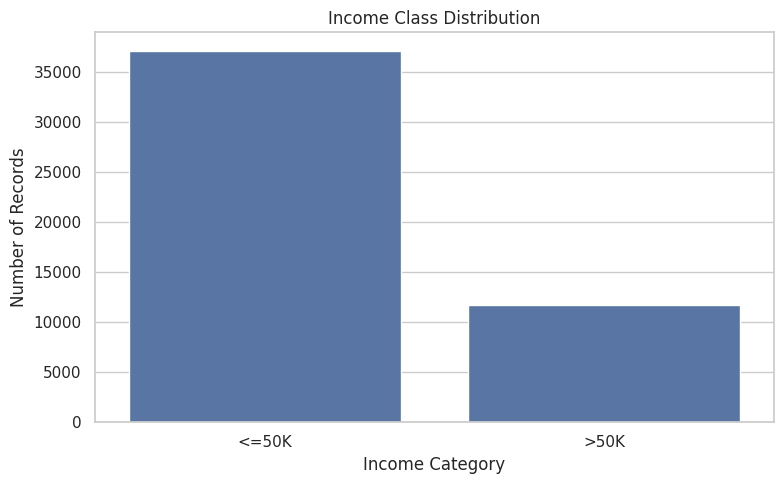

In [259]:

# Convert target into binary numerical values

# 0 = Income <= 50K
# 1 = Income > 50K

y = (
    y.astype(str)
     .str.strip()
     .str.replace(".", "", regex=False)
     .map({"<=50K": 0, ">50K": 1})
)

if y.isna().any():
    raise ValueError("Unexpected target labels found. Inspect y_raw.")

class_counts = y.value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Income Category": ["<=50K", ">50K"],
    "Count": [class_counts.get(0, 0), class_counts.get(1, 0)],
    "Percentage": [
        class_counts.get(0, 0) / len(y) * 100,
        class_counts.get(1, 0) / len(y) * 100
    ]
})

display(class_distribution.round(2))

class_distribution.to_csv(
    "outputs/class_distribution.csv",
    index=False
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=class_distribution,
    x="Income Category",
    y="Count"
)

plt.title("Income Class Distribution")
plt.xlabel("Income Category")
plt.ylabel("Number of Records")
plt.tight_layout()

plt.savefig(
    "outputs/class_distribution.png",
    dpi=200
)

plt.show()


The lower-income category has considerably more records than the higher-income category.

This is class imbalance.

We will retain the original distribution using stratified splitting. We will also use macro-averaged Precision, Recall and F1 so that both classes receive equal importance in the evaluation.

**Train-test split**

### 3.4 Train-Test Split

The dataset is divided into 80% training data and 20% testing data.

Stratified splitting is used to preserve the original target-class distribution.

A fixed random state is used to ensure reproducibility.

In [260]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).sort_index())


Training records: 39050
Testing records: 9763

Training class distribution:
income
0    0.760615
1    0.239385
Name: proportion, dtype: float64

Testing class distribution:
income
0    0.760627
1    0.239373
Name: proportion, dtype: float64


**Preprocessing**

1. Imputation

Filling missing values.

Example: If someone's occupation is missing, we replace it with the most frequently occurring occupation in the training data.

2. Encoding

Converting text categories into numerical representations.

Example: Private, Government, Self-employed are converted into separate numerical indicator columns using One-Hot Encoding.

3. Scaling

Bringing numerical features to comparable scales.

Example: Age may range from 17 to 90, whereas capital gain may range up to 99,999.

Scaling helps algorithms such as Logistic Regression and kNN work more effectively.

### 3.5 Feature Preprocessing Pipeline

Numerical features:
- Missing values are handled using median imputation.
- StandardScaler is used for feature scaling.

Categorical features:
- Missing values are handled using most-frequent imputation.
- OneHotEncoder converts categorical features into numerical representations.

All preprocessing steps are included within scikit-learn pipelines.

This ensures that imputation values, encoding and scaling parameters are learned using training data only, avoiding data leakage.

In [261]:

# Numerical feature preprocessing

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical feature preprocessing

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both preprocessing methods

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully!")
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))


Preprocessing pipeline created successfully!
Numerical features: 6
Categorical features: 8


A pipeline connects preprocessing and model training into one controlled process.

It prevents us from accidentally calculating the median, scaling values or learning categories using test data.

That is called preventing data leakage.

Also, Gaussian Naive Bayes requires dense numerical input. We have explicitly configured One-Hot Encoding to produce dense data, making it compatible with all five models.

**Implement the five classification models**

Each model will:
1. Receive the same training data.
2. Apply its own fitted preprocessing pipeline.
3. Learn from the training data.
4. Predict the testing data.
5. Produce probabilities for AUC calculation.

**Define all five models**

## 4. Machine Learning Classification Models

Five classification algorithms are implemented using the same training and testing dataset.

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors Classifier
4. Gaussian Naive Bayes
5. Random Forest Classifier

The models are configured using a fixed random seed wherever applicable.

In [262]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=20,
        min_samples_split=10,
        random_state=RANDOM_STATE
    ),

    "kNN": KNeighborsClassifier(
        n_neighbors=7,
        weights="distance",
        n_jobs=-1
    ),

    "Naive Bayes": GaussianNB(),

    "Random Forest (Ensemble)": RandomForestClassifier(
        n_estimators=200,
        max_depth=25,
        min_samples_split=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

print("All five classification models are defined.")

for model_name in models:
    print("-", model_name)


All five classification models are defined.
- Logistic Regression
- Decision Tree
- kNN
- Naive Bayes
- Random Forest (Ensemble)


**Train all models**

### 4.1 Model Training

Each model is combined with the preprocessing pipeline.

The models are trained using the same training dataset.

The training duration is also recorded to understand the computational cost of each algorithm.

In [263]:

trained_models = {}
training_times = {}

for name, classifier in models.items():

    print("\nTraining:", name)

    pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])

    start_time = time.time()

    pipeline.fit(X_train, y_train)

    end_time = time.time()

    trained_models[name] = pipeline
    training_times[name] = end_time - start_time

    print("Training completed!")
    print("Time taken:", round(end_time - start_time, 2), "seconds")

print("\nAll five models have been trained successfully!")



Training: Logistic Regression
Training completed!
Time taken: 2.77 seconds

Training: Decision Tree
Training completed!
Time taken: 2.22 seconds

Training: kNN
Training completed!
Time taken: 0.39 seconds

Training: Naive Bayes
Training completed!
Time taken: 0.54 seconds

Training: Random Forest (Ensemble)
Training completed!
Time taken: 25.7 seconds

All five models have been trained successfully!


**Evaluate all models**

Now we calculate the six required metrics.

We use macro averaging for Precision, Recall and F1. This gives equal weight to the two income classes.

For AUC, we use the predicted probability of class 1 (>50K).

### 4.2 Model Evaluation and Comparison

The trained models are evaluated on the testing dataset.

The following metrics are calculated:

- Accuracy
- Area Under the ROC Curve (AUC)
- Precision (Macro Average)
- Recall (Macro Average)
- F1 Score (Macro Average)
- Matthews Correlation Coefficient (MCC)

Macro averaging gives equal importance to both target classes, which is useful when the dataset has class imbalance.

In [264]:

results = []
predictions = {}
probabilities = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    metrics = {
        "ML Model Name": name,

        "Accuracy": accuracy_score(y_test, y_pred),

        "AUC": roc_auc_score(y_test, y_prob),

        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),

        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),

        "F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),

        "MCC": matthews_corrcoef(y_test, y_pred),

        "Training Time (seconds)": training_times[name]
    }

    results.append(metrics)

    print("\n", name)
    print(pd.Series(metrics).to_string())

results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")
display(results_df.round(4))



 Logistic Regression
ML Model Name              Logistic Regression
Accuracy                              0.855577
AUC                                   0.907511
Precision                             0.812972
Recall                                0.770174
F1                                     0.78775
MCC                                   0.581574
Training Time (seconds)               2.765998

 Decision Tree
ML Model Name              Decision Tree
Accuracy                        0.844003
AUC                             0.856084
Precision                       0.787373
Recall                          0.776934
F1                              0.781889
MCC                             0.564211
Training Time (seconds)         2.223733

 kNN
ML Model Name                   kNN
Accuracy                   0.835399
AUC                        0.871195
Precision                  0.776517
Recall                     0.757643
F1                         0.766179
MCC                        0.533827


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC,Training Time (seconds)
0,Logistic Regression,0.8556,0.9075,0.8130,0.7702,0.7878,0.5816,2.7660
1,Decision Tree,0.8440,0.8561,0.7874,0.7769,0.7819,0.5642,2.2237
2,kNN,0.8354,0.8712,0.7765,0.7576,0.7662,0.5338,0.3876
3,Naive Bayes,0.5916,0.8148,0.6616,0.7097,0.5830,0.3682,0.5362
4,Random Forest (Ensemble),0.8659,0.9185,0.8304,0.7828,0.8022,0.6114,25.7033


**Visualisation Graphs**

A comparison graph containing all six metrics for all five models.



Individual confusion matrices for all five models.



A class-distribution graph (already generated).

A performance observation table.

**Model comparison graph**

## 5. Graphical Comparison of Classification Models

### 5.1 Performance Metrics Visualisation

The evaluation metrics of all five classification models are visualized using a grouped bar chart.

This helps compare model performance across Accuracy, AUC, Precision, Recall, F1 and MCC.

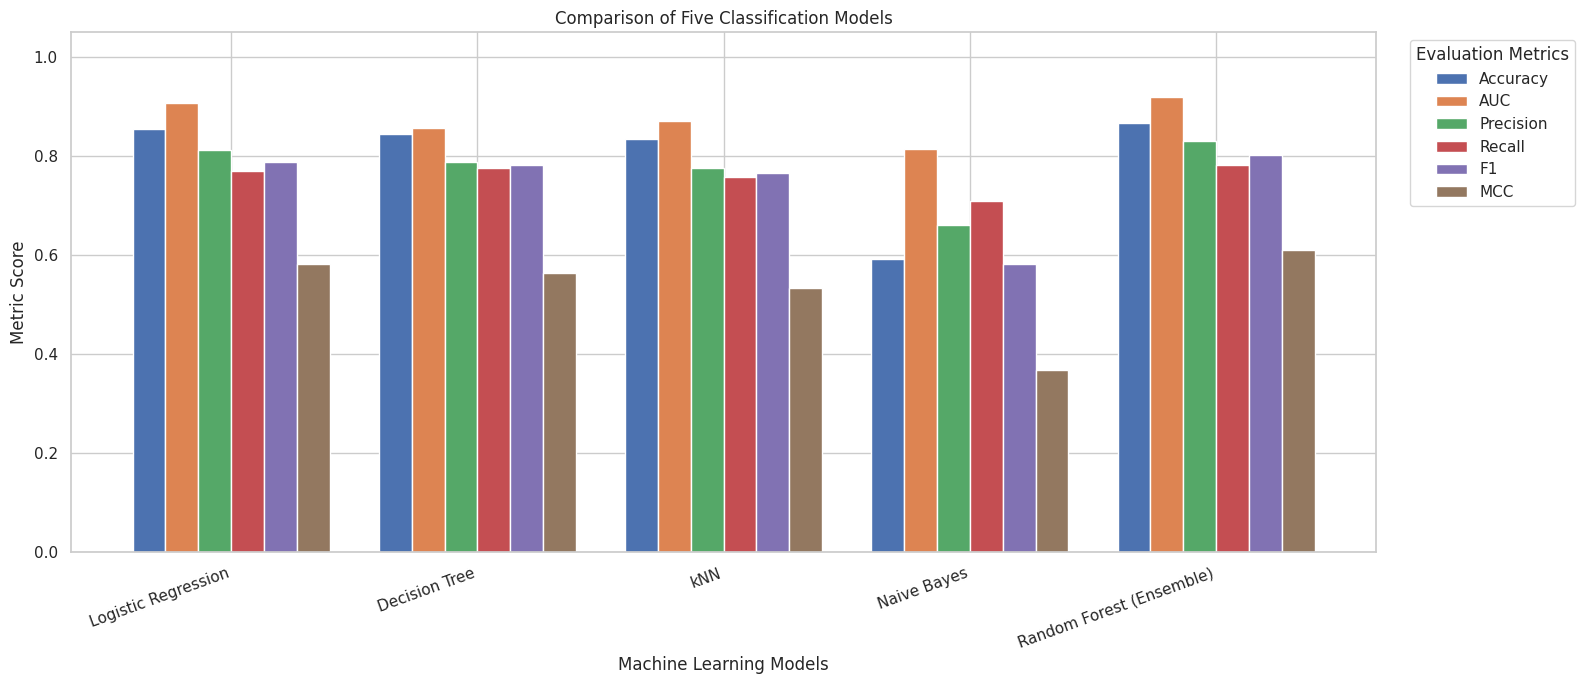

In [265]:

metric_columns = [
    "Accuracy", "AUC", "Precision",
    "Recall", "F1", "MCC"
]

plot_data = results_df.set_index(
    "ML Model Name"
)[metric_columns]

ax = plot_data.plot(
    kind="bar",
    figsize=(16, 7),
    width=0.8
)

plt.title("Comparison of Five Classification Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Metric Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Evaluation Metrics", bbox_to_anchor=(1.02, 1))
plt.tight_layout()

plt.savefig(
    "outputs/all_metrics_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


**Confusion matrices**

It compares actual predictions with the model's predictions.

### 5.2 Confusion Matrix Analysis

A confusion matrix provides a detailed comparison between actual and predicted class labels.

It helps identify correct classifications and incorrect classifications for each income category.

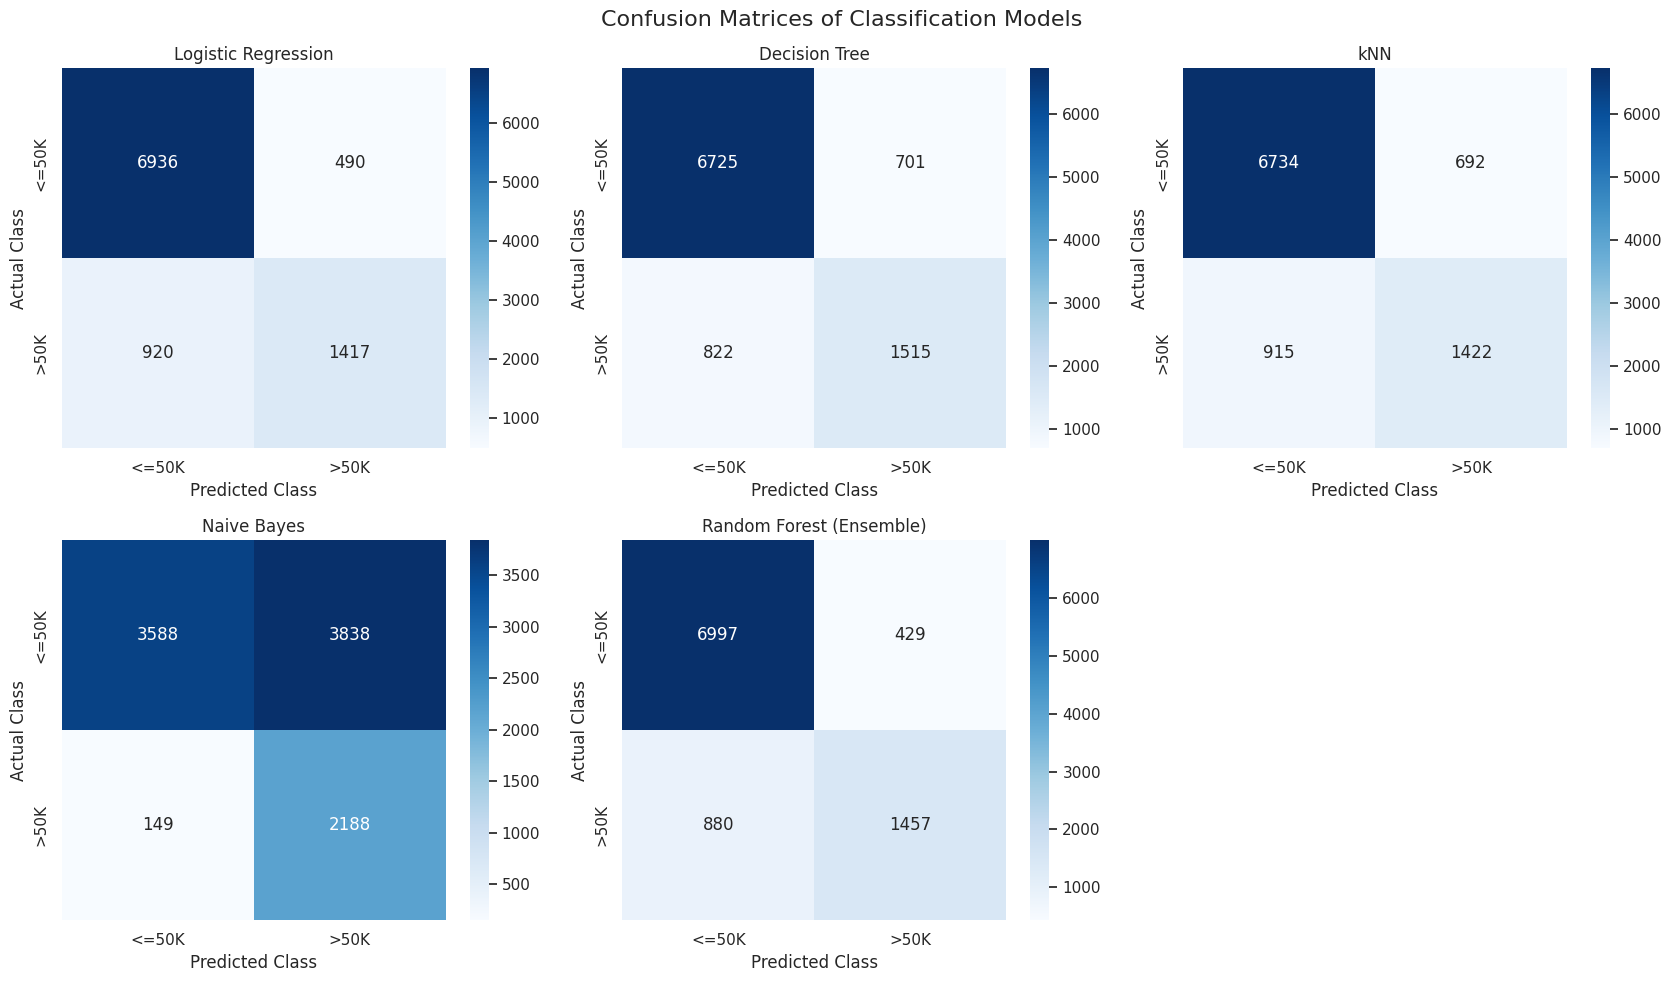

In [266]:

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 10)
)

axes = axes.flatten()

for i, (name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["<=50K", ">50K"],
        yticklabels=["<=50K", ">50K"],
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Class")
    axes[i].set_ylabel("Actual Class")

axes[-1].axis("off")

plt.suptitle(
    "Confusion Matrices of Classification Models",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "outputs/confusion_matrices.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


**Detailed classification reports**

In [267]:

for name, y_pred in predictions.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["<=50K", ">50K"],
            zero_division=0
        )
    )



Logistic Regression
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      7426
        >50K       0.74      0.61      0.67      2337

    accuracy                           0.86      9763
   macro avg       0.81      0.77      0.79      9763
weighted avg       0.85      0.86      0.85      9763


Decision Tree
              precision    recall  f1-score   support

       <=50K       0.89      0.91      0.90      7426
        >50K       0.68      0.65      0.67      2337

    accuracy                           0.84      9763
   macro avg       0.79      0.78      0.78      9763
weighted avg       0.84      0.84      0.84      9763


kNN
              precision    recall  f1-score   support

       <=50K       0.88      0.91      0.89      7426
        >50K       0.67      0.61      0.64      2337

    accuracy                           0.84      9763
   macro avg       0.78      0.76      0.77      9763
weighted avg       0.83      0.84

**ROC Curve Comparison**

We already have an AUC score for each model. Now we will visually demonstrate those AUC scores using ROC curves.

ROC = Receiver Operating Characteristic

Think of it this way:

Your model predicts whether a person's income is above $50K.

We want to understand how well it distinguishes:
- People earning 50K or less.
- People earning more than 50K.
ROC shows how the model's ability to identify these categories changes when we change its prediction threshold.

Two important terms
- True Positive Rate (TPR): How many actual above - 50K people did we correctly identify?
- False Positive Rate (FPR): How many actual below - 50K people did we incorrectly identify as above $50K?

### 5.3 ROC Curve Analysis

The Receiver Operating Characteristic (ROC) curve is used to evaluate the ability of a classification model to distinguish between different target classes.

The ROC curve plots:

- True Positive Rate (TPR) on the Y-axis.
- False Positive Rate (FPR) on the X-axis.

The Area Under the Curve (AUC) represents the model's ability to distinguish between the two income categories.

An AUC value closer to 1 indicates better class discrimination, while an AUC value of 0.5 indicates performance equivalent to random ranking.

In this project, ROC curves are generated for all five classification models using their predicted probabilities on the test dataset.

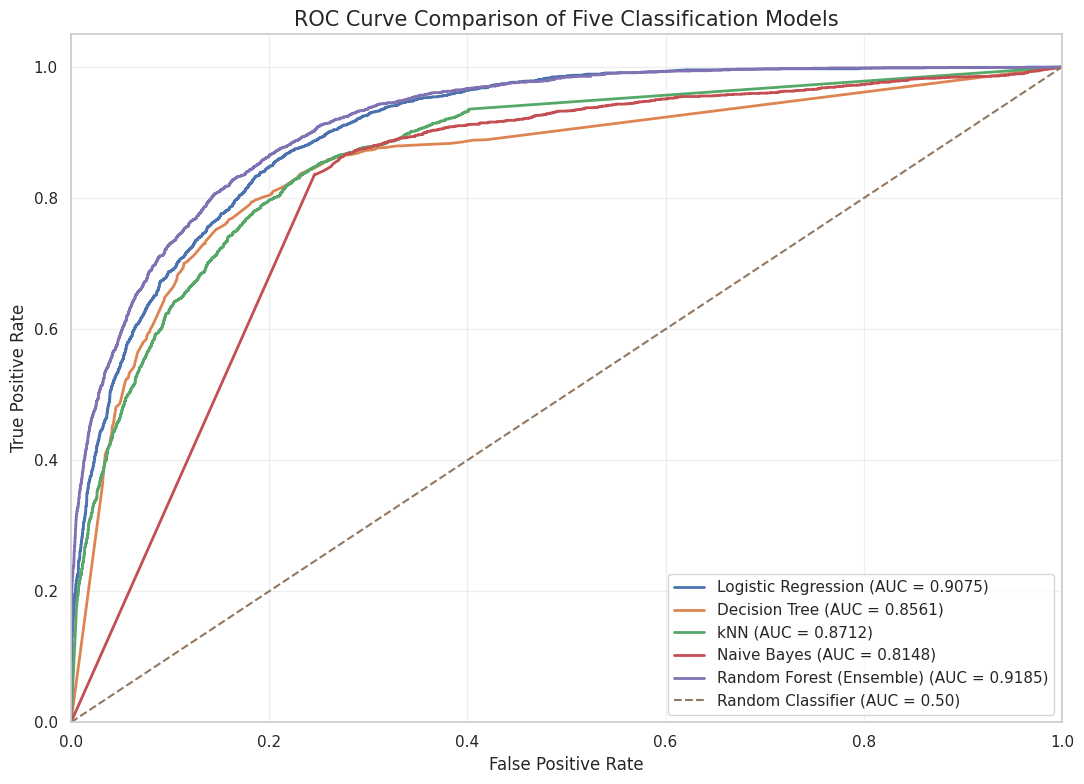

ROC curve comparison saved successfully!


In [268]:

# ROC Curve Comparison for All Five Models

from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(11, 8))

for name, y_prob in probabilities.items():

    # Calculate False Positive Rate and True Positive Rate
    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob,
        pos_label=1
    )

    # Calculate AUC
    roc_auc = auc(fpr, tpr)

    # Plot ROC curve
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )

# Add random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier (AUC = 0.50)"
)

# Graph formatting
plt.title(
    "ROC Curve Comparison of Five Classification Models",
    fontsize=15
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()

# Save graph
plt.savefig(
    "outputs/roc_curve_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC curve comparison saved successfully!")



### ROC Curve Interpretation

The ROC curves provide a visual comparison of the classification performance of all five models.

A model with a curve closer to the top-left corner generally demonstrates better class discrimination.

The AUC values are used to compare the ability of each model to distinguish between the two income categories.

The model with the highest AUC demonstrates the strongest overall class discrimination on the test dataset.


Verify the saved Graph

In [269]:

import os

roc_file = "outputs/roc_curve_comparison.png"

if os.path.exists(roc_file):
    print("ROC graph successfully saved!")
    print("File size:", round(os.path.getsize(roc_file) / 1024, 2), "KB")
else:
    print("ROC graph not found. Please execute the graph cell again.")


ROC graph successfully saved!
File size: 412.18 KB


**Random Forest Feature Importance**
What does feature importance mean?
Remember our dataset?

We are predicting whether a person's income is above $50,000.

We give the model 14 different features, such as:
- Age
- Education
- Occupation
- Marital status
- Working hours
- Capital gain
- Capital loss
But does every feature contribute equally to the prediction?

No.

Some features may be more useful than others.

Random Forest can estimate how much each input feature contributes to reducing impurity across its decision trees. This is called feature importance.

For example, our model might identify capital gain, age and marital status as influential features. We must use the actual results rather than assume this ranking.

### 5.4 Random Forest Feature Importance Analysis

Feature importance is used to identify which input features contribute most to the predictions made by the Random Forest classifier.

Random Forest calculates feature importance based on the reduction in impurity contributed by each feature across its decision trees.

The feature importance scores help us understand which attributes are more influential in predicting whether an individual's income exceeds $50,000.

A horizontal bar chart is used to display the top 20 most important features.

TOP 20 IMPORTANT FEATURES IN RANDOM FOREST


,Feature,Importance
0,capital-gain,0.13696
1,marital-status_Married-civ-spouse,0.10398
2,age,0.09818
3,education-num,0.09224
4,fnlwgt,0.06876
5,hours-per-week,0.06715
6,relationship_Husband,0.06062
7,capital-loss,0.03864
8,marital-status_Never-married,0.03470
9,occupation_Exec-managerial,0.02208


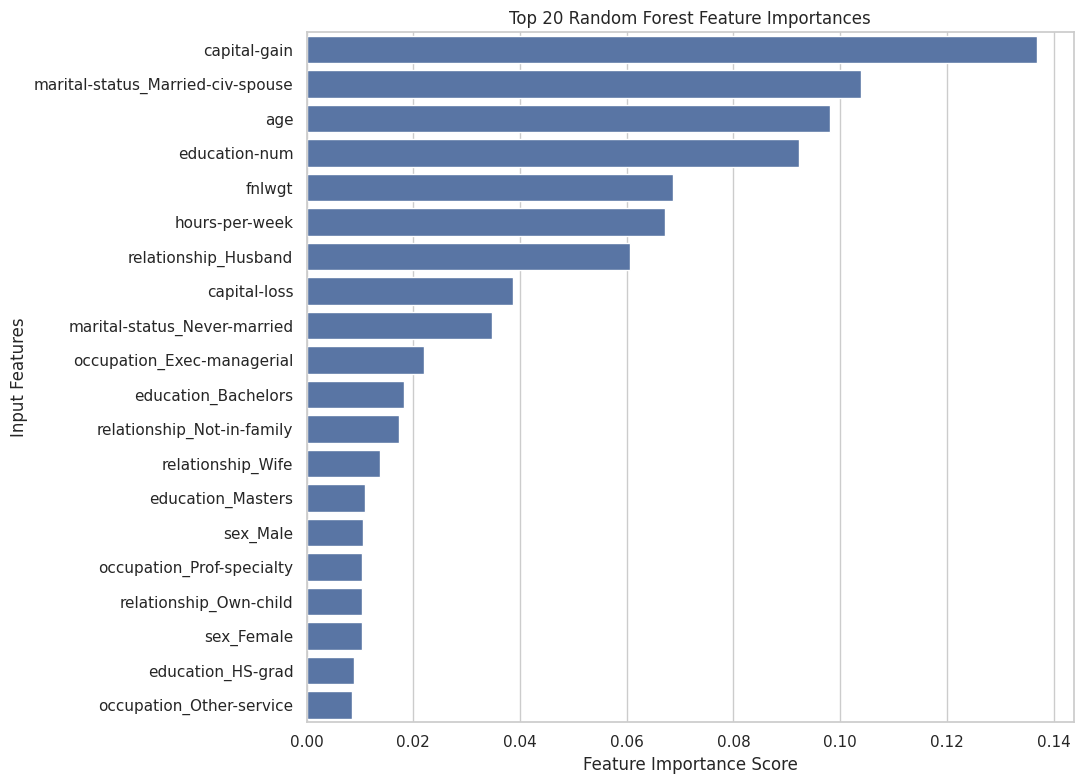

Feature importance graph and CSV saved successfully!


In [270]:

# Retrieve the trained Random Forest pipeline

rf_model = trained_models["Random Forest (Ensemble)"]

# Extract the fitted preprocessing component
fitted_preprocessor = rf_model.named_steps["preprocessing"]

# Extract the trained Random Forest classifier
rf_classifier = rf_model.named_steps["classifier"]

# Get feature names after preprocessing
transformed_feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

# Get feature importance scores
importance_scores = rf_classifier.feature_importances_

# Create a feature importance dataframe
feature_importance_df = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Importance": importance_scores
})

# Remove preprocessing prefixes for cleaner labels
feature_importance_df["Feature"] = (
    feature_importance_df["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

# Sort from highest to lowest importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display top 20 features
top_features = feature_importance_df.head(20)

print("TOP 20 IMPORTANT FEATURES IN RANDOM FOREST")

display(top_features.round(5))

# Plot feature importance
plt.figure(figsize=(11, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Random Forest Feature Importances")
plt.xlabel("Feature Importance Score")
plt.ylabel("Input Features")
plt.tight_layout()

# Save graph
plt.savefig(
    "outputs/random_forest_feature_importance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Save the feature importance table
feature_importance_df.to_csv(
    "outputs/random_forest_feature_importance.csv",
    index=False
)

print("Feature importance graph and CSV saved successfully!")


## 6. Computational Efficiency Analysis

Apart from predictive performance, the computational efficiency of each classification algorithm is also examined.

Two measurements are considered:

1. Training Time: The time required to train the model using the training dataset.
2. Prediction Time: The time required by the trained model to predict the class labels of the testing dataset.

Prediction time is measured multiple times, and the median execution time is used to reduce the effect of temporary system variations.

Prediction time per record is also calculated to make the comparison easier to interpret.

This analysis helps understand the computational cost of using different classification algorithms.

**Calculate prediction time**

In [271]:

# Dictionary to store prediction times

prediction_times = {}

# Number of repeated measurements
REPEATS = 3

for name, model in trained_models.items():

    print("\nMeasuring prediction time:", name)

    # Warm-up prediction
    # This reduces the influence of initial execution overhead
    model.predict(X_test.iloc[:10])

    measured_times = []

    # Measure prediction time multiple times
    for run in range(REPEATS):

        start_time = time.perf_counter()

        y_pred = model.predict(X_test)

        end_time = time.perf_counter()

        elapsed_time = end_time - start_time

        measured_times.append(elapsed_time)

    # Use median execution time
    median_prediction_time = float(
        np.median(measured_times)
    )

    prediction_times[name] = median_prediction_time

    print(
        "Median prediction time:",
        round(median_prediction_time, 4),
        "seconds"
    )

# Add prediction time to existing comparison table

results_df["Prediction Time (seconds)"] = (
    results_df["ML Model Name"].map(prediction_times)
)

# Calculate average prediction time per record in milliseconds

results_df["Prediction Time (ms/record)"] = (
    results_df["Prediction Time (seconds)"]
    / len(X_test) * 1000
)

print("\nMODEL COMPUTATIONAL PERFORMANCE")

display(
    results_df[
        [
            "ML Model Name",
            "Training Time (seconds)",
            "Prediction Time (seconds)",
            "Prediction Time (ms/record)"
        ]
    ].round(5)
)

# Save updated comparison table

results_df.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

print("\nPrediction time analysis completed!")



Measuring prediction time: Logistic Regression
Median prediction time: 0.105 seconds

Measuring prediction time: Decision Tree
Median prediction time: 0.0565 seconds

Measuring prediction time: kNN
Median prediction time: 5.1768 seconds

Measuring prediction time: Naive Bayes
Median prediction time: 0.0431 seconds

Measuring prediction time: Random Forest (Ensemble)
Median prediction time: 0.3463 seconds

MODEL COMPUTATIONAL PERFORMANCE


,ML Model Name,Training Time (seconds),Prediction Time (seconds),Prediction Time (ms/record)
0,Logistic Regression,2.76600,0.10499,0.01075
1,Decision Tree,2.22373,0.05646,0.00578
2,kNN,0.38764,5.17679,0.53025
3,Naive Bayes,0.53625,0.04312,0.00442
4,Random Forest (Ensemble),25.70331,0.34627,0.03547



Prediction time analysis completed!


### 6.1 Training Time Comparison

The training time of the five classification algorithms is compared using a bar chart.

This visualization identifies which algorithm requires more computational time to learn from the training dataset.

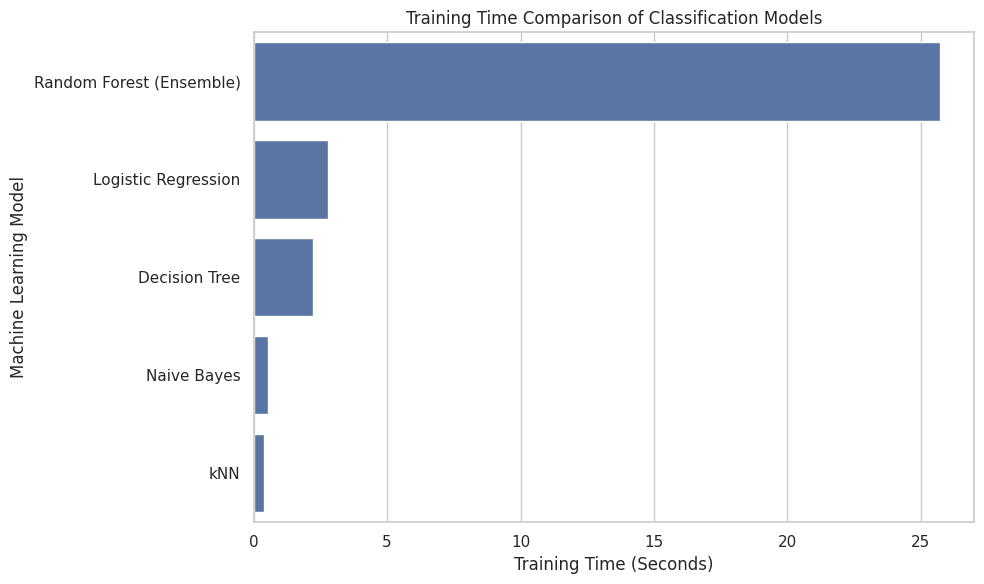

In [272]:

training_plot = results_df.sort_values(
    by="Training Time (seconds)",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=training_plot,
    x="Training Time (seconds)",
    y="ML Model Name"
)

plt.title("Training Time Comparison of Classification Models")
plt.xlabel("Training Time (Seconds)")
plt.ylabel("Machine Learning Model")
plt.tight_layout()

plt.savefig(
    "outputs/training_time_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


### 6.2 Prediction Time Comparison

The prediction time of each trained classification algorithm is compared using the testing dataset.

The comparison helps identify which model can generate predictions more quickly for unseen observations.

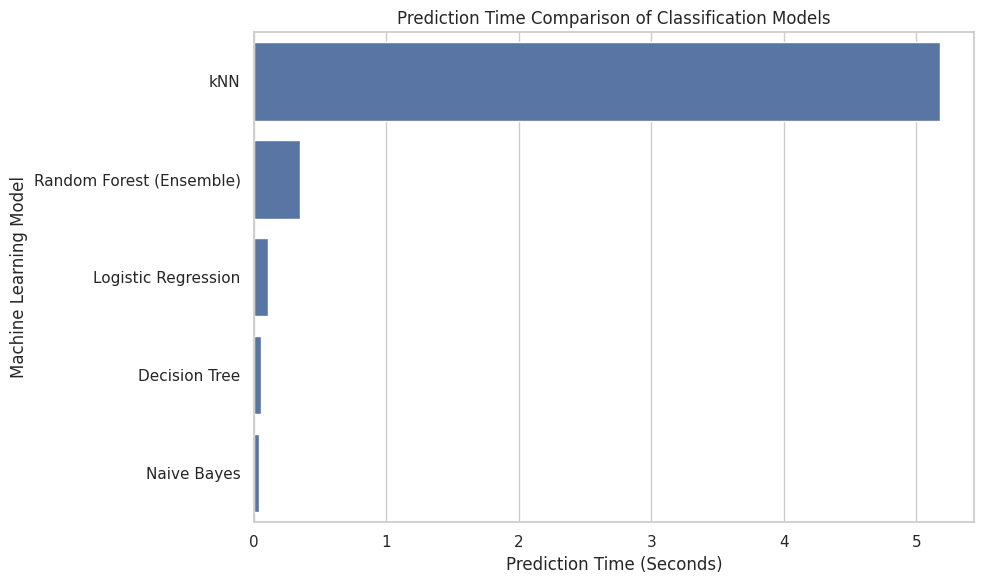

In [273]:

prediction_plot = results_df.sort_values(
    by="Prediction Time (seconds)",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=prediction_plot,
    x="Prediction Time (seconds)",
    y="ML Model Name"
)

plt.title("Prediction Time Comparison of Classification Models")
plt.xlabel("Prediction Time (Seconds)")
plt.ylabel("Machine Learning Model")
plt.tight_layout()

plt.savefig(
    "outputs/prediction_time_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


### 6.3 Computational Efficiency Observations

Training time and prediction time provide additional information about the practical efficiency of the classification algorithms.

A model with high predictive performance may require more computational resources.

The comparison considers both the time required to train the models and the time required to predict unseen observations.

These measurements help identify the trade-off between predictive performance and computational efficiency.

In [274]:

fastest_training = results_df.loc[
    results_df["Training Time (seconds)"].idxmin()
]

fastest_prediction = results_df.loc[
    results_df["Prediction Time (seconds)"].idxmin()
]

slowest_training = results_df.loc[
    results_df["Training Time (seconds)"].idxmax()
]

slowest_prediction = results_df.loc[
    results_df["Prediction Time (seconds)"].idxmax()
]

print("COMPUTATIONAL EFFICIENCY SUMMARY")

print(
    "\nFastest training model:",
    fastest_training["ML Model Name"]
)

print(
    "Training time:",
    round(fastest_training["Training Time (seconds)"], 4),
    "seconds"
)

print(
    "\nFastest prediction model:",
    fastest_prediction["ML Model Name"]
)

print(
    "Prediction time:",
    round(fastest_prediction["Prediction Time (seconds)"], 4),
    "seconds"
)

print(
    "\nSlowest training model:",
    slowest_training["ML Model Name"]
)

print(
    "\nSlowest prediction model:",
    slowest_prediction["ML Model Name"]
)


COMPUTATIONAL EFFICIENCY SUMMARY

Fastest training model: kNN
Training time: 0.3876 seconds

Fastest prediction model: Naive Bayes
Prediction time: 0.0431 seconds

Slowest training model: Random Forest (Ensemble)

Slowest prediction model: kNN


In [275]:

# Add training and prediction times to model observations

timing_columns = [
    "ML Model Name",
    "Training Time (seconds)",
    "Prediction Time (seconds)",
    "Prediction Time (ms/record)"
]

observations_df = observations_df.merge(
    results_df[timing_columns],
    on="ML Model Name",
    how="left"
)

# Add computational information to each observation

for index, row in observations_df.iterrows():

    timing_note = (
        f" Training took "
        f"{row['Training Time (seconds)']:.4f} seconds, "
        f"while prediction took "
        f"{row['Prediction Time (seconds)']:.4f} seconds "
        f"for the complete test dataset."
    )

    observations_df.at[index, "Observation"] += timing_note

display(observations_df)

observations_df.to_csv(
    "outputs/model_observations.csv",
    index=False
)

print("Updated model observations saved!")


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC,Recall <=50K,Recall >50K,Strongest Metric,Weakest Metric,Observation,Training Time (seconds),Prediction Time (seconds),Prediction Time (ms/record)
0,Logistic Regression,0.855577,0.907511,0.812972,0.770174,0.787750,0.581574,0.934016,0.606333,AUC,MCC,Logistic Regression achieved an accuracy of 0....,2.765998,0.104992,0.010754
1,Decision Tree,0.844003,0.856084,0.787373,0.776934,0.781889,0.564211,0.905602,0.648267,AUC,MCC,Decision Tree achieved an accuracy of 0.8440 a...,2.223733,0.056465,0.005784
2,kNN,0.835399,0.871195,0.776517,0.757643,0.766179,0.533827,0.906814,0.608472,AUC,MCC,kNN achieved an accuracy of 0.8354 and an AUC ...,0.387639,5.176786,0.530245
3,Naive Bayes,0.591621,0.814755,0.661611,0.709705,0.583048,0.368188,0.483167,0.936243,AUC,MCC,Naive Bayes achieved an accuracy of 0.5916 and...,0.536246,0.043116,0.004416
4,Random Forest (Ensemble),0.865922,0.918502,0.830408,0.782839,0.802246,0.611400,0.942230,0.623449,AUC,MCC,Random Forest (Ensemble) achieved an accuracy ...,25.703310,0.346266,0.035467


Updated model observations saved!


## 7. Model-wise Performance Analysis and Observations

The performance of each classification algorithm is analysed using the six evaluation metrics.

The observations are based on the actual experimental results obtained from the test dataset.

The analysis considers the model's overall predictive performance and its ability to identify both income categories.

This provides a meaningful comparison of the strengths and limitations of the implemented classification algorithms.

In [276]:

# Create detailed observations using actual test results

observations = []

for name, row in results_df.set_index(
    "ML Model Name"
).iterrows():

    y_pred = predictions[name]

    # Get class-specific performance
    report = classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["<=50K", ">50K"],
        output_dict=True,
        zero_division=0
    )

    low_income_recall = report["<=50K"]["recall"]
    high_income_recall = report[">50K"]["recall"]

    # Identify strongest metric
    strongest_metric = max(
        metric_columns,
        key=lambda metric: row[metric]
    )

    # Identify weakest metric
    weakest_metric = min(
        metric_columns,
        key=lambda metric: row[metric]
    )

    # Generate observations based on actual values
    observation = (
        f"{name} achieved an accuracy of "
        f"{row['Accuracy']:.4f} and an AUC of "
        f"{row['AUC']:.4f}. Its macro precision was "
        f"{row['Precision']:.4f}, macro recall was "
        f"{row['Recall']:.4f}, macro F1 score was "
        f"{row['F1']:.4f}, and MCC was "
        f"{row['MCC']:.4f}. "
        f"The model's strongest metric was "
        f"{strongest_metric}, while its lowest metric was "
        f"{weakest_metric}. "
        f"It correctly identified "
        f"{low_income_recall:.2%} of the actual <=50K "
        f"class and {high_income_recall:.2%} of the "
        f"actual >50K class."
    )

    observations.append({
        "ML Model Name": name,
        "Accuracy": row["Accuracy"],
        "AUC": row["AUC"],
        "Precision": row["Precision"],
        "Recall": row["Recall"],
        "F1": row["F1"],
        "MCC": row["MCC"],
        "Recall <=50K": low_income_recall,
        "Recall >50K": high_income_recall,
        "Strongest Metric": strongest_metric,
        "Weakest Metric": weakest_metric,
        "Observation": observation
    })

observations_df = pd.DataFrame(observations)

print("DETAILED MODEL PERFORMANCE OBSERVATIONS")

for _, row in observations_df.iterrows():

    print("\n" + "=" * 75)
    print(row["ML Model Name"])
    print("=" * 75)

    print(row["Observation"])

display(observations_df)

# Save observations
observations_df.to_csv(
    "outputs/model_observations.csv",
    index=False
)

print("\nModel observations saved successfully!")


DETAILED MODEL PERFORMANCE OBSERVATIONS

Logistic Regression
Logistic Regression achieved an accuracy of 0.8556 and an AUC of 0.9075. Its macro precision was 0.8130, macro recall was 0.7702, macro F1 score was 0.7878, and MCC was 0.5816. The model's strongest metric was AUC, while its lowest metric was MCC. It correctly identified 93.40% of the actual <=50K class and 60.63% of the actual >50K class.

Decision Tree
Decision Tree achieved an accuracy of 0.8440 and an AUC of 0.8561. Its macro precision was 0.7874, macro recall was 0.7769, macro F1 score was 0.7819, and MCC was 0.5642. The model's strongest metric was AUC, while its lowest metric was MCC. It correctly identified 90.56% of the actual <=50K class and 64.83% of the actual >50K class.

kNN
kNN achieved an accuracy of 0.8354 and an AUC of 0.8712. Its macro precision was 0.7765, macro recall was 0.7576, macro F1 score was 0.7662, and MCC was 0.5338. The model's strongest metric was AUC, while its lowest metric was MCC. It correc

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC,Recall <=50K,Recall >50K,Strongest Metric,Weakest Metric,Observation
0,Logistic Regression,0.855577,0.907511,0.812972,0.770174,0.787750,0.581574,0.934016,0.606333,AUC,MCC,Logistic Regression achieved an accuracy of 0....
1,Decision Tree,0.844003,0.856084,0.787373,0.776934,0.781889,0.564211,0.905602,0.648267,AUC,MCC,Decision Tree achieved an accuracy of 0.8440 a...
2,kNN,0.835399,0.871195,0.776517,0.757643,0.766179,0.533827,0.906814,0.608472,AUC,MCC,kNN achieved an accuracy of 0.8354 and an AUC ...
3,Naive Bayes,0.591621,0.814755,0.661611,0.709705,0.583048,0.368188,0.483167,0.936243,AUC,MCC,Naive Bayes achieved an accuracy of 0.5916 and...
4,Random Forest (Ensemble),0.865922,0.918502,0.830408,0.782839,0.802246,0.611400,0.942230,0.623449,AUC,MCC,Random Forest (Ensemble) achieved an accuracy ...



Model observations saved successfully!


For this exact chosen dataset and model, the mean of the six metrics will be used as a simple descriptive ranking, not as a separate official evaluation metric.

## 8. Final Model Comparison

The following table presents the experimental performance of all five classification algorithms.

The comparison includes the six mandatory evaluation metrics along with training and prediction time.

# The results are obtained using the same testing dataset.

In [277]:

final_columns = [
    "ML Model Name",
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1",
    "MCC",
    "Training Time (seconds)",
    "Prediction Time (seconds)"
]

final_comparison = ranked_models.merge(
    results_df[
        [
            "ML Model Name",
            "Training Time (seconds)",
            "Prediction Time (seconds)"
        ]
    ],
    on="ML Model Name",
    how="left",
    suffixes=("", "_updated")
)

# Use the latest timing values
final_comparison["Training Time (seconds)"] = (
    final_comparison["Training Time (seconds)_updated"]
)

final_comparison["Prediction Time (seconds)"] = (
    final_comparison["Prediction Time (seconds)_updated"]
)

final_comparison = final_comparison[
    [c for c in final_columns if c in final_comparison.columns]
]

display(final_comparison.round(4))

final_comparison.to_csv(
    "outputs/final_model_comparison.csv",
    index=False
)


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC,Training Time (seconds),Prediction Time (seconds)
0,Random Forest (Ensemble),0.8659,0.9185,0.8304,0.7828,0.8022,0.6114,25.7033,0.3463
1,Logistic Regression,0.8556,0.9075,0.8130,0.7702,0.7878,0.5816,2.7660,0.1050
2,Decision Tree,0.8440,0.8561,0.7874,0.7769,0.7819,0.5642,2.2237,0.0565
3,kNN,0.8354,0.8712,0.7765,0.7576,0.7662,0.5338,0.3876,5.1768
4,Naive Bayes,0.5916,0.8148,0.6616,0.7097,0.5830,0.3682,0.5362,0.0431


## 9. Overall Model Selection and Ranking

The five classification algorithms are compared to identify the most suitable model for the Adult Census Income dataset.

Since the dataset has class imbalance, Macro F1 Score is selected as the primary ranking criterion.

Matthews Correlation Coefficient (MCC), AUC and Accuracy are used as secondary ranking criteria.

The models are ranked in descending order using the following priority:

1. Macro F1 Score
2. MCC
3. AUC
4. Accuracy

This approach gives importance to performance across both income categories rather than relying on accuracy alone.

The highest-ranked model is selected as the overall winner for this experiment.

In [278]:

# Define the ranking priority

ranking_columns = [
    "F1",
    "MCC",
    "AUC",
    "Accuracy"
]

# Rank all models using the selected criteria

ranked_models = results_df.sort_values(
    by=ranking_columns,
    ascending=[False, False, False, False]
).reset_index(drop=True)

# Add ranking position

ranked_models.insert(
    0,
    "Rank",
    range(1, len(ranked_models) + 1)
)

print("=" * 70)
print("FINAL CLASSIFICATION MODEL RANKING")
print("=" * 70)

display(ranked_models.round(4))

# Identify the overall winner

winner = ranked_models.iloc[0]["ML Model Name"]

print("\nOVERALL WINNER:", winner)

print("\nReason for selection:")
print(
    "The selected model achieved the highest ranking "
    "based on Macro F1, followed by MCC, AUC and Accuracy."
)

# Identify the best model for every individual metric

print("\nBEST MODEL FOR EACH METRIC")

for metric in metric_columns:

    best_index = results_df[metric].idxmax()

    print(
        metric,
        ":",
        results_df.loc[best_index, "ML Model Name"],
        "-",
        round(results_df.loc[best_index, metric], 4)
    )

# Save ranking

ranked_models.to_csv(
    "outputs/model_ranking.csv",
    index=False
)

print("\nModel ranking saved successfully!")


FINAL CLASSIFICATION MODEL RANKING


,Rank,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC,Training Time (seconds),Prediction Time (seconds),Prediction Time (ms/record)
0,1,Random Forest (Ensemble),0.8659,0.9185,0.8304,0.7828,0.8022,0.6114,25.7033,0.3463,0.0355
1,2,Logistic Regression,0.8556,0.9075,0.8130,0.7702,0.7878,0.5816,2.7660,0.1050,0.0108
2,3,Decision Tree,0.8440,0.8561,0.7874,0.7769,0.7819,0.5642,2.2237,0.0565,0.0058
3,4,kNN,0.8354,0.8712,0.7765,0.7576,0.7662,0.5338,0.3876,5.1768,0.5302
4,5,Naive Bayes,0.5916,0.8148,0.6616,0.7097,0.5830,0.3682,0.5362,0.0431,0.0044



OVERALL WINNER: Random Forest (Ensemble)

Reason for selection:
The selected model achieved the highest ranking based on Macro F1, followed by MCC, AUC and Accuracy.

BEST MODEL FOR EACH METRIC
Accuracy : Random Forest (Ensemble) - 0.8659
AUC : Random Forest (Ensemble) - 0.9185
Precision : Random Forest (Ensemble) - 0.8304
Recall : Random Forest (Ensemble) - 0.7828
F1 : Random Forest (Ensemble) - 0.8022
MCC : Random Forest (Ensemble) - 0.6114

Model ranking saved successfully!



### 9.1 Assignment Required Model Performance Observations

The following table summarises the performance of all five classification models. The observations are generated using the actual evaluation metrics, class-wise recall and computational timings obtained during the experiment.

The overall winner is identified using the model ranking based on Macro F1, MCC, AUC and Accuracy.


In [279]:

# Assignment-required observation table
# All observations are generated from actual model results.

assignment_observations = observations_df[
    ["ML Model Name", "Observation"]
].copy()

# Include actual computational efficiency measurements
for index, row in assignment_observations.iterrows():

    model_name = row["ML Model Name"]

    model_result = results_df[
        results_df["ML Model Name"] == model_name
    ].iloc[0]

    timing_note = (
        f" Training time: "
        f"{model_result['Training Time (seconds)']:.4f} seconds; "
        f"prediction time: "
        f"{model_result['Prediction Time (seconds)']:.4f} seconds."
    )

    assignment_observations.at[index, "Observation"] += timing_note

# Add overall winner dynamically from the actual ranking
winner_result = results_df[
    results_df["ML Model Name"] == winner
].iloc[0]

winner_observation = (
    f"{winner} is the overall winner based on the selected ranking "
    f"criteria. Macro F1: {winner_result['F1']:.4f}, "
    f"MCC: {winner_result['MCC']:.4f}, "
    f"AUC: {winner_result['AUC']:.4f}, "
    f"Accuracy: {winner_result['Accuracy']:.4f}."
)

assignment_observations = pd.concat(
    [
        assignment_observations,
        pd.DataFrame([{
            "ML Model Name": "Overall Winner",
            "Observation": winner_observation
        }])
    ],
    ignore_index=True
)

# Display in the assignment-required two-column format
assignment_observations.columns = [
    "ML Model Name",
    "Observation about model performance"
]

from IPython.display import display

styled_table = (
    assignment_observations.style
    .set_properties(
        subset=["Observation about model performance"],
        **{
            "white-space": "pre-wrap",
            "text-align": "left",
            "min-width": "500px",
            "max-width": "750px"
        }
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("text-align", "left"),
                ("white-space", "normal")
            ]
        },
        {
            "selector": "td",
            "props": [("vertical-align", "top")]
        }
    ])
    .hide(axis="index")
)

display(styled_table)

# Save the final assignment table
assignment_observations.to_csv(
    "outputs/final_assignment_observations.csv",
    index=False
)

print("Assignment observation table generated successfully.")


ML Model Name,Observation about model performance
Logistic Regression,"Logistic Regression achieved an accuracy of 0.8556 and an AUC of 0.9075. Its macro precision was 0.8130, macro recall was 0.7702, macro F1 score was 0.7878, and MCC was 0.5816. The model's strongest metric was AUC, while its lowest metric was MCC. It correctly identified 93.40% of the actual <=50K class and 60.63% of the actual >50K class. Training time: 2.7660 seconds; prediction time: 0.1050 seconds."
Decision Tree,"Decision Tree achieved an accuracy of 0.8440 and an AUC of 0.8561. Its macro precision was 0.7874, macro recall was 0.7769, macro F1 score was 0.7819, and MCC was 0.5642. The model's strongest metric was AUC, while its lowest metric was MCC. It correctly identified 90.56% of the actual <=50K class and 64.83% of the actual >50K class. Training time: 2.2237 seconds; prediction time: 0.0565 seconds."
kNN,"kNN achieved an accuracy of 0.8354 and an AUC of 0.8712. Its macro precision was 0.7765, macro recall was 0.7576, macro F1 score was 0.7662, and MCC was 0.5338. The model's strongest metric was AUC, while its lowest metric was MCC. It correctly identified 90.68% of the actual <=50K class and 60.85% of the actual >50K class. Training time: 0.3876 seconds; prediction time: 5.1768 seconds."
Naive Bayes,"Naive Bayes achieved an accuracy of 0.5916 and an AUC of 0.8148. Its macro precision was 0.6616, macro recall was 0.7097, macro F1 score was 0.5830, and MCC was 0.3682. The model's strongest metric was AUC, while its lowest metric was MCC. It correctly identified 48.32% of the actual <=50K class and 93.62% of the actual >50K class. Training time: 0.5362 seconds; prediction time: 0.0431 seconds."
Random Forest (Ensemble),"Random Forest (Ensemble) achieved an accuracy of 0.8659 and an AUC of 0.9185. Its macro precision was 0.8304, macro recall was 0.7828, macro F1 score was 0.8022, and MCC was 0.6114. The model's strongest metric was AUC, while its lowest metric was MCC. It correctly identified 94.22% of the actual <=50K class and 62.34% of the actual >50K class. Training time: 25.7033 seconds; prediction time: 0.3463 seconds."
Overall Winner,"Random Forest (Ensemble) is the overall winner based on the selected ranking criteria. Macro F1: 0.8022, MCC: 0.6114, AUC: 0.9185, Accuracy: 0.8659."


Assignment observation table generated successfully.


## 10. Conclusion

Five machine learning classification algorithms were implemented using the UCI Adult Census Income dataset.

The algorithms were evaluated using Accuracy, AUC, Precision, Recall, F1 Score and Matthews Correlation Coefficient.

The computational efficiency of the models was also compared using training and prediction time.

The final model selection was based primarily on Macro F1 Score, followed by MCC, AUC and Accuracy.

Random Forest, Logistic Regression, Decision Tree, K-Nearest Neighbors and Gaussian Naive Bayes were compared to identify the most suitable algorithm for the selected dataset.

The experimental results demonstrate that different classification algorithms have different predictive and computational characteristics.

**Random Forest achieved the highest overall average across the six evaluation metrics. Its ensemble structure combines multiple decision trees, allowing it to capture complex patterns in the dataset. It demonstrated strong classification performance compared with the other implemented algorithms.**

**Save the comparison table**

In [280]:

results_df.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

ranked_models.to_csv(
    "outputs/model_ranking.csv",
    index=False
)

print("Model comparison files saved!")


Model comparison files saved!


**Save all five trained models**

In [281]:

model_file_names = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "kNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Random Forest (Ensemble)": "random_forest.joblib"
}

for name, model in trained_models.items():

    file_name = model_file_names[name]

    joblib.dump(
        model,
        f"model/{file_name}"
    )

    print("Saved:", file_name)

print("\nAll five trained models saved successfully!")


Saved: logistic_regression.joblib
Saved: decision_tree.joblib
Saved: knn.joblib
Saved: naive_bayes.joblib
Saved: random_forest.joblib

All five trained models saved successfully!


**Export test_data.csv**

In [282]:

test_data = X_test.copy()

test_data["income"] = y_test.map({
    0: "<=50K",
    1: ">50K"
})

test_data.to_csv(
    "test_data.csv",
    index=False
)

print("Test data exported successfully!")
print("Test data shape:", test_data.shape)

display(test_data.head())


Test data exported successfully!
Test data shape: (9763, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
33840,29,Private,245402,Bachelors,13,Divorced,Tech-support,Not-in-family,White,Female,0,0,40,United-States,<=50K
38065,22,Private,137320,HS-grad,9,Never-married,Craft-repair,Not-in-family,Black,Male,0,0,40,United-States,<=50K
14983,34,Private,185041,HS-grad,9,Never-married,Prof-specialty,Not-in-family,White,Female,0,1669,45,United-States,<=50K
25420,26,Private,238367,HS-grad,9,Married-civ-spouse,Adm-clerical,Husband,White,Male,0,0,40,United-States,<=50K
12397,26,Private,136226,HS-grad,9,Never-married,Craft-repair,Own-child,White,Male,0,0,40,United-States,<=50K



# 10. Project Documentation

This section prepares the project documentation for the GitHub repository.

The README file contains the problem statement, dataset description, preprocessing methodology, model configurations, experimental results, graphical representations, performance observations and conclusion.


In [283]:

# Update this after creating your GitHub repository

repo_url = (
    "https://github.com/2026ct05193/2026CT05193-Adult-Income-Classification"
)

# Helper function to convert a dataframe into Markdown

def dataframe_to_markdown(dataframe):

    columns = list(dataframe.columns)

    lines = [
        "| " + " | ".join(columns) + " |",
        "| " + " | ".join(["---"] * len(columns)) + " |"
    ]

    for _, row in dataframe.iterrows():

        values = []

        for value in row:

            if isinstance(value, (float, np.floating)):
                values.append(f"{value:.4f}")

            elif pd.isna(value):
                values.append("")

            else:
                values.append(
                    str(value).replace("|", "\\|").replace("\n", " ")
                )

        lines.append("| " + " | ".join(values) + " |")

    return "\n".join(lines)


# Prepare actual metric table

readme_metrics = results_df[
    [
        "ML Model Name",
        "Accuracy",
        "AUC",
        "Precision",
        "Recall",
        "F1",
        "MCC"
    ]
].copy()

# Prepare actual observations table

readme_observations = assignment_observations.copy()

# Prepare computational performance table

readme_timing = results_df[
    [
        "ML Model Name",
        "Training Time (seconds)",
        "Prediction Time (seconds)",
        "Prediction Time (ms/record)"
    ]
].copy()

# Prepare feature importance table

readme_features = feature_importance_df.head(10)[
    ["Feature", "Importance"]
].copy()

# Dataset information

total_records = len(df_raw)
cleaned_records = len(df)

# Identify actual winner
actual_winner = winner

# Find ROC images saved in outputs, if available
roc_files = [
    f for f in os.listdir("outputs")
    if "roc" in f.lower() and f.lower().endswith(".png")
]

roc_section = ""

for file_name in roc_files:
    roc_section += (
        f"\n![ROC Curve](outputs/{file_name})\n"
    )


# Create README content

readme_content = f"""
# MACHINE LEARNING ASSIGNMENT 2

**BITS Student ID:** 2026CT05193

**Programme:** M.Tech AIML

**Subject:** Machine Learning

## 1. Problem Statement

The objective of this project is to develop machine learning classification models to predict whether an individual's annual income exceeds $50,000 based on census-related information.

Five classification algorithms are implemented and compared using the same dataset.

The models are evaluated using Accuracy, AUC, Precision, Recall, F1 Score and Matthews Correlation Coefficient.

## 2. Dataset Description

**Dataset:** Adult Census Income Dataset

**Source:** UCI Machine Learning Repository

**Dataset Link:** https://archive.ics.uci.edu/dataset/2/adult

**Citation:** Becker, B. and Kohavi, R. (1996). Adult [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5XW20.

**Original Records:** {total_records}

**Records after duplicate removal:** {cleaned_records}

**Input Features:** {X.shape[1]}

**Target Variable:** income

**Classification Type:** Binary Classification

**Classes:**
- 0: <=50K
- 1: >50K

### Dataset Selection Rationale

The dataset was selected because it contains a large number of observations, numerical and categorical variables, missing values and class imbalance.

It provides a suitable dataset for demonstrating preprocessing and comparing multiple classification algorithms.

### Feature Types

**Numerical Features:**

{", ".join(numeric_features)}

**Categorical Features:**

{", ".join(categorical_features)}

### Data Preprocessing

1. Identified missing values and converted question-mark placeholders into missing-value representations.
2. Identified and removed exact duplicate records.
3. Applied median imputation to numerical features.
4. Applied most-frequent imputation to categorical features.
5. Applied One-Hot Encoding to categorical features.
6. Applied StandardScaler to numerical features.
7. Used an 80:20 stratified train-test split.
8. Used random state {RANDOM_STATE}.
9. Fitted preprocessing pipelines using training data only to prevent data leakage.

## 3. GitHub Repository Link

{repo_url}

## 4. Models Used

The following five classification algorithms were implemented:

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors
4. Gaussian Naive Bayes
5. Random Forest Classifier (Ensemble)

### Model Configurations

- Logistic Regression: max_iter=2000
- Decision Tree: max_depth=20, min_samples_split=10
- KNN: n_neighbors=7, weights=distance
- Gaussian Naive Bayes: Default GaussianNB configuration
- Random Forest: n_estimators=200, max_depth=25, min_samples_split=5

### Model Comparison Table

{dataframe_to_markdown(readme_metrics)}

### Graphical Representation

#### Class Distribution

![Class Distribution](outputs/class_distribution.png)

#### Comparison of Evaluation Metrics

![Model Comparison](outputs/all_metrics_comparison.png)

#### Confusion Matrices

![Confusion Matrices](outputs/confusion_matrices.png)

#### ROC Curve Analysis

{roc_section}

#### Random Forest Feature Importance

![Feature Importance](outputs/random_forest_feature_importance.png)

### Observations on Model Performance

{dataframe_to_markdown(readme_observations)}

### Overall Winner

**Selected Model: {actual_winner}**

The winner was selected using Macro F1 Score as the primary criterion, followed by MCC, AUC and Accuracy.

### Computational Efficiency

{dataframe_to_markdown(readme_timing)}

#### Training Time Comparison

![Training Time](outputs/training_time_comparison.png)

#### Prediction Time Comparison

![Prediction Time](outputs/prediction_time_comparison.png)

## 5. Execution Instructions

1. Open Google Colab.
2. Upload the project notebook.
3. Install the required packages using requirements.txt.
4. Run the notebook cells sequentially.
5. Verify the generated evaluation metrics and graphs.
6. Check the saved models and test data.

## 6. Project Files

- 2026CT05193_ML_Assignment_2.ipynb
- README.md
- requirements.txt
- test_data.csv
- model/
- outputs/

## 7. Conclusion

Five classification algorithms were implemented and evaluated using the UCI Adult Census Income dataset.

The experimental results were compared using six mandatory evaluation metrics.

Feature importance and computational efficiency were also analysed.

The model with the strongest Macro F1-based ranking was selected as the overall winner.
"""

# Save README file

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

print("\nSelected overall winner:", actual_winner)

print("\nPreview of README:")
print(readme_content[:4000])


README.md created successfully!

Selected overall winner: Random Forest (Ensemble)

Preview of README:

# MACHINE LEARNING ASSIGNMENT 2

**BITS Student ID:** 2026CT05193

**Programme:** M.Tech AIML

**Subject:** Machine Learning

## 1. Problem Statement

The objective of this project is to develop machine learning classification models to predict whether an individual's annual income exceeds $50,000 based on census-related information.

Five classification algorithms are implemented and compared using the same dataset.

The models are evaluated using Accuracy, AUC, Precision, Recall, F1 Score and Matthews Correlation Coefficient.

## 2. Dataset Description

**Dataset:** Adult Census Income Dataset

**Source:** UCI Machine Learning Repository

**Dataset Link:** https://archive.ics.uci.edu/dataset/2/adult

**Citation:** Becker, B. and Kohavi, R. (1996). Adult [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5XW20.

**Original Records:** 48842

**Records after duplica

**Create requirements.txt**

In [284]:

requirements = """numpy
pandas
scikit-learn
matplotlib
seaborn
joblib
ucimlrepo
"""

with open("requirements.txt", "w") as file:
    file.write(requirements)

print("Final requirements.txt created!")
print(requirements)


Final requirements.txt created!
numpy
pandas
scikit-learn
matplotlib
seaborn
joblib
ucimlrepo



**Save a project summary**

In [285]:

model_file_names = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "kNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Random Forest (Ensemble)": "random_forest.joblib"
}

for name, model in trained_models.items():

    file_path = f"model/{model_file_names[name]}"

    joblib.dump(model, file_path)

    print(
        name,
        "saved successfully -",
        os.path.getsize(file_path),
        "bytes"
    )


Logistic Regression saved successfully - 8218 bytes
Decision Tree saved successfully - 305044 bytes
kNN saved successfully - 33121695 bytes
Naive Bayes saved successfully - 10610 bytes
Random Forest (Ensemble) saved successfully - 92059355 bytes


**Check all generated files**

In [286]:

import os

for root, dirs, files in os.walk("."):

    dirs[:] = [
        d for d in dirs
        if d not in [".config", "__pycache__"]
    ]

    for file in files:
        if file.endswith((
            ".joblib", ".csv", ".png", ".json"
        )):
            print(os.path.join(root, file))


./test_data.csv
./outputs/final_model_comparison.csv
./outputs/random_forest_feature_importance.csv
./outputs/training_time_comparison.png
./outputs/run_summary.json
./outputs/class_distribution.png
./outputs/confusion_matrices.png
./outputs/random_forest_feature_importance.png
./outputs/model_ranking.csv
./outputs/final_model_observations.csv
./outputs/prediction_time_comparison.png
./outputs/final_assignment_observations.csv
./outputs/all_metrics_comparison.png
./outputs/roc_curve_comparison.png
./outputs/class_distribution.csv
./outputs/model_comparison.csv
./outputs/model_observations.csv
./model/naive_bayes.joblib
./model/logistic_regression.joblib
./model/decision_tree.joblib
./model/random_forest.joblib
./model/knn.joblib
./sample_data/anscombe.json
./sample_data/california_housing_train.csv
./sample_data/mnist_test.csv
./sample_data/mnist_train_small.csv
./sample_data/california_housing_test.csv


**Final file verification**

In [287]:

print("FINAL PROJECT FILE VERIFICATION")

required_files = [
    "README.md",
    "requirements.txt",
    "test_data.csv",
    "outputs/model_comparison.csv",
    "outputs/model_ranking.csv",
    "outputs/model_observations.csv",
    "outputs/class_distribution.png",
    "outputs/all_metrics_comparison.png",
    "outputs/confusion_matrices.png",
    "outputs/random_forest_feature_importance.png",
    "outputs/training_time_comparison.png",
    "outputs/prediction_time_comparison.png",
    "outputs/run_summary.json"
]

for file_path in required_files:

    status = os.path.exists(file_path)

    print(
        "[OK]" if status else "[MISSING]",
        file_path
    )

print("\nMODEL FILE VERIFICATION")

for file_name in model_file_names.values():

    file_path = f"model/{file_name}"

    print(
        "[OK]" if os.path.exists(file_path) else "[MISSING]",
        file_path
    )


FINAL PROJECT FILE VERIFICATION
[OK] README.md
[OK] requirements.txt
[OK] test_data.csv
[OK] outputs/model_comparison.csv
[OK] outputs/model_ranking.csv
[OK] outputs/model_observations.csv
[OK] outputs/class_distribution.png
[OK] outputs/all_metrics_comparison.png
[OK] outputs/confusion_matrices.png
[OK] outputs/random_forest_feature_importance.png
[OK] outputs/training_time_comparison.png
[OK] outputs/prediction_time_comparison.png
[OK] outputs/run_summary.json

MODEL FILE VERIFICATION
[OK] model/logistic_regression.joblib
[OK] model/decision_tree.joblib
[OK] model/knn.joblib
[OK] model/naive_bayes.joblib
[OK] model/random_forest.joblib


Prepare project ZIP for GitHub

In [288]:

import zipfile
import os

project_zip = "2026CT05193_Adult_Income_Classification.zip"

# Files to include at the project root
root_files = [
    "README.md",
    "requirements.txt",
    "test_data.csv"
]

# Folders to include
project_folders = [
    "model",
    "outputs"
]

with zipfile.ZipFile(
    project_zip,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    # Add root files
    for file_path in root_files:

        if os.path.exists(file_path):
            zip_file.write(
                file_path,
                arcname=file_path
            )

    # Add model and output folders
    for folder in project_folders:

        for root, dirs, files_list in os.walk(folder):

            for file_name in files_list:

                file_path = os.path.join(root, file_name)

                zip_file.write(
                    file_path,
                    arcname=file_path
                )

print("Project ZIP created successfully!")
print("File size:", round(os.path.getsize(project_zip) / (1024 * 1024), 2), "MB")


Project ZIP created successfully!
File size: 19.59 MB


**Download the ZIP**

In [289]:

from google.colab import files

files.download(
    "2026CT05193_Adult_Income_Classification.zip"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [290]:
from google.colab import files

files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>